# Лабораторная работа № 3. Кластеризация

## 1. Введение

**Цель:** изучить методы кластеризации, оценить качество разбиения и содержательно интерпретировать полученные группы объектов.

**Задачи:** исследовать структуру реальных измерений, оценить распределения и выбросы; выбрать информативные признаки, стандартизировать их; сравнить **K-means** и **иерархическую агломеративную кластеризацию (Ward)**; обосновать число кластеров методами локтя, силуэта и дендрограммой; исследовать влияние параметров и устойчивость результатов; проанализировать центры, расстояния и двумерную проекцию PCA.

Известные сорта риса используются **только для внешней проверки**, а не для построения кластеров или настройки алгоритмов. Все расчёты воспроизводимы (`random_state = 42`).

## 2. Выбор и исследование датасета
### 2.1. Источник и описание данных

Использован набор **Rice (Cammeo and Osmancik)** из **UCI Machine Learning Repository**: https://archive.ics.uci.edu/dataset/545/rice+cammeo+and+osmancik. Изображения рисовых зёрен двух разновидностей были преобразованы в геометрические измерения. Выборка включает **3810 наблюдений** и **7 числовых признаков**:

| Столбец | Смысл |
|---|---|
| `Area` | площадь зерна, пиксели² |
| `Perimeter` | периметр контура, пиксели |
| `Major_Axis_Length` | длина главной оси аппроксимирующего эллипса, пиксели |
| `Minor_Axis_Length` | длина малой оси, пиксели |
| `Eccentricity` | эксцентриситет аппроксимирующего эллипса |
| `Convex_Area` | площадь выпуклой оболочки, пиксели² |
| `Extent` | доля заполнения ограничивающего прямоугольника |
| `Class` | известный сорт (`Cammeo` / `Osmancik`) — **эталон, не признак** |

### 2.2. Почему эти данные подходят для кластеризации

Признаки числовые, имеют физически понятный смысл и множество различных значений, поэтому позволяют построить содержательные матрицы рассеивания. Сорта известны, но методы работают **без учителя**: метки `Class` из матрицы объектов исключены. Наличие эталонных классов позволяет независимо оценить ARI, Rand, NMI и другие внешние метрики. Совпадение кластеров с сортами **не гарантируется** и не должно принудительно задавать число кластеров.

### 2.3. Загрузка датасета из ARFF

Исходный `Rice_Cammeo_Osmancik.arff` поместить **рядом с `.ipynb`**. Формат ARFF считывается через `scipy.io.arff`; строковый столбец `Class` нужно декодировать из `bytes`. CSV-конвертация не нужна. Чтение файла не обращается в интернет.

In [1]:
from pathlib import Path
from itertools import combinations

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display
from scipy.io import arff
from scipy.cluster.hierarchy import linkage, dendrogram, cut_tree
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.decomposition import PCA
from sklearn.metrics import (
    silhouette_score, calinski_harabasz_score, davies_bouldin_score,
    adjusted_rand_score, rand_score, normalized_mutual_info_score,
    homogeneity_score, completeness_score, v_measure_score, pairwise_distances
)
from matplotlib.lines import Line2D

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 145)
sns.set_theme(style="whitegrid", context="notebook", palette="deep")
plt.rcParams.update({"font.family": "DejaVu Sans", "figure.dpi": 110,
                     "axes.titlesize": 11, "axes.labelsize": 10})
RANDOM_STATE = 42

DATA_PATH = Path("Rice_Cammeo_Osmancik.arff")
# Для экспорта в .py разрешаем запуск из другого рабочего каталога.
if not DATA_PATH.exists() and "__file__" in globals():
    DATA_PATH = Path(__file__).resolve().parent / DATA_PATH.name
if not DATA_PATH.exists():
    raise FileNotFoundError(
        "Не найден Rice_Cammeo_Osmancik.arff. Разместите файл в одной папке "
        "с ноутбуком и запускайте Jupyter из этой папки."
    )

raw_records, arff_metadata = arff.loadarff(DATA_PATH)
df = pd.DataFrame(raw_records)
# В ARFF номинальные значения читаются как bytes.
df["Class"] = df["Class"].map(
    lambda x: x.decode("utf-8") if isinstance(x, bytes) else str(x)
)

FEATURE_DESCRIPTIONS = {
    "Area": "Площадь, пиксели²", "Perimeter": "Периметр, пиксели",
    "Major_Axis_Length": "Большая ось, пиксели", "Minor_Axis_Length": "Малая ось, пиксели",
    "Eccentricity": "Эксцентриситет", "Convex_Area": "Выпуклая площадь, пиксели²",
    "Extent": "Заполнение прямоугольника"
}
ALL_NUMERIC = list(FEATURE_DESCRIPTIONS)
assert df.shape == (3810, 8), "Размерность отличается от ожидаемой для UCI Rice"
assert set(df["Class"].unique()) == {"Cammeo", "Osmancik"}
print(f"Загружено {len(df)} наблюдений, {df.shape[1]} столбцов")
display(df.head())

Загружено 3810 наблюдений, 8 столбцов


,Area,Perimeter,Major_Axis_Length,Minor_Axis_Length,Eccentricity,Convex_Area,Extent,Class
0,15231.0,525.578979,229.749878,85.093788,0.928882,15617.0,0.572896,Cammeo
1,14656.0,494.311005,206.020065,91.730972,0.895405,15072.0,0.615436,Cammeo
2,14634.0,501.122009,214.106781,87.768288,0.912118,14954.0,0.693259,Cammeo
3,13176.0,458.342987,193.337387,87.448395,0.891861,13368.0,0.640669,Cammeo
4,14688.0,507.166992,211.743378,89.312454,0.906691,15262.0,0.646024,Cammeo


### 2.4. Первичная проверка качества данных

Проверим типы столбцов, пропуски, дубликаты, доли классов и наличие `inf`. Визуализация и построение кластеров выполняются только после этой проверки.

In [2]:
print("Информация о датасете:")
df.info()
quality = pd.DataFrame({
    "Тип": df.dtypes.astype(str),
    "Пропусков": df.isna().sum(),
    "Уникальных значений": df.nunique()
})
display(quality)
print("Полных дубликатов:", int(df.duplicated().sum()))
print("Не конечных чисел:", int((~np.isfinite(df[ALL_NUMERIC].to_numpy())).sum()))
assert df[ALL_NUMERIC].notna().all().all()
assert np.isfinite(df[ALL_NUMERIC].to_numpy()).all()

class_counts = df["Class"].value_counts().rename_axis("Сорт").to_frame("Количество")
class_counts["Доля, %"] = (100 * class_counts["Количество"] / len(df)).round(2)
display(class_counts)

Информация о датасете:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3810 entries, 0 to 3809
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Area               3810 non-null   float64
 1   Perimeter          3810 non-null   float64
 2   Major_Axis_Length  3810 non-null   float64
 3   Minor_Axis_Length  3810 non-null   float64
 4   Eccentricity       3810 non-null   float64
 5   Convex_Area        3810 non-null   float64
 6   Extent             3810 non-null   float64
 7   Class              3810 non-null   object 
dtypes: float64(7), object(1)
memory usage: 238.3+ KB


,Тип,Пропусков,Уникальных значений
Area,float64,0,2828
Perimeter,float64,0,3738
Major_Axis_Length,float64,0,3808
Minor_Axis_Length,float64,0,3804
Eccentricity,float64,0,3803
Convex_Area,float64,0,2857
Extent,float64,0,3804
Class,object,0,2


Полных дубликатов: 0
Не конечных чисел: 0


,Количество,"Доля, %"
Сорт,,
Osmancik,2180,57.22
Cammeo,1630,42.78


#### Вывод по первичной проверке

Проверено **3810 × 8**: семь вещественных измерений и эталонная категория `Class`. Пропущенных и не конечных значений, а также полных дубликатов **нет**. Доли сортов составляют **Cammeo — 1630 (42,78%)** и **Osmancik — 2180 (57,22%)**. Этот дисбаланс не мешает кластеризации: `Class` не подаётся алгоритмам.

### 2.5. Распределения и описательные статистики

По гистограммам и коэффициенту асимметрии оценим отличие эмпирических распределений от симметричной нормальной формы. Нормальность **не обязательна** для K-means или Ward, но форма распределений важна для анализа плотности и крайних значений.

Числовые характеристики всех семи исходных признаков:


,count,mean,std,min,25%,50%,75%,max,Skewness,Уникальных значений
Area,3810.0,12667.728,1732.368,7551.000,11370.500,12421.500,13950.000,18913.000,0.325,2828
Perimeter,3810.0,454.239,35.597,359.100,426.145,448.852,483.684,548.446,0.221,3738
Major_Axis_Length,3810.0,188.776,17.449,145.264,174.354,185.810,203.550,239.010,0.260,3808
Minor_Axis_Length,3810.0,86.314,5.730,59.532,82.732,86.435,90.144,107.542,-0.135,3804
Eccentricity,3810.0,0.887,0.021,0.777,0.872,0.889,0.903,0.948,-0.449,3803
Convex_Area,3810.0,12952.497,1776.972,7723.000,11626.250,12706.500,14284.000,19099.000,0.320,2857
Extent,3810.0,0.662,0.077,0.497,0.599,0.645,0.727,0.861,0.344,3804


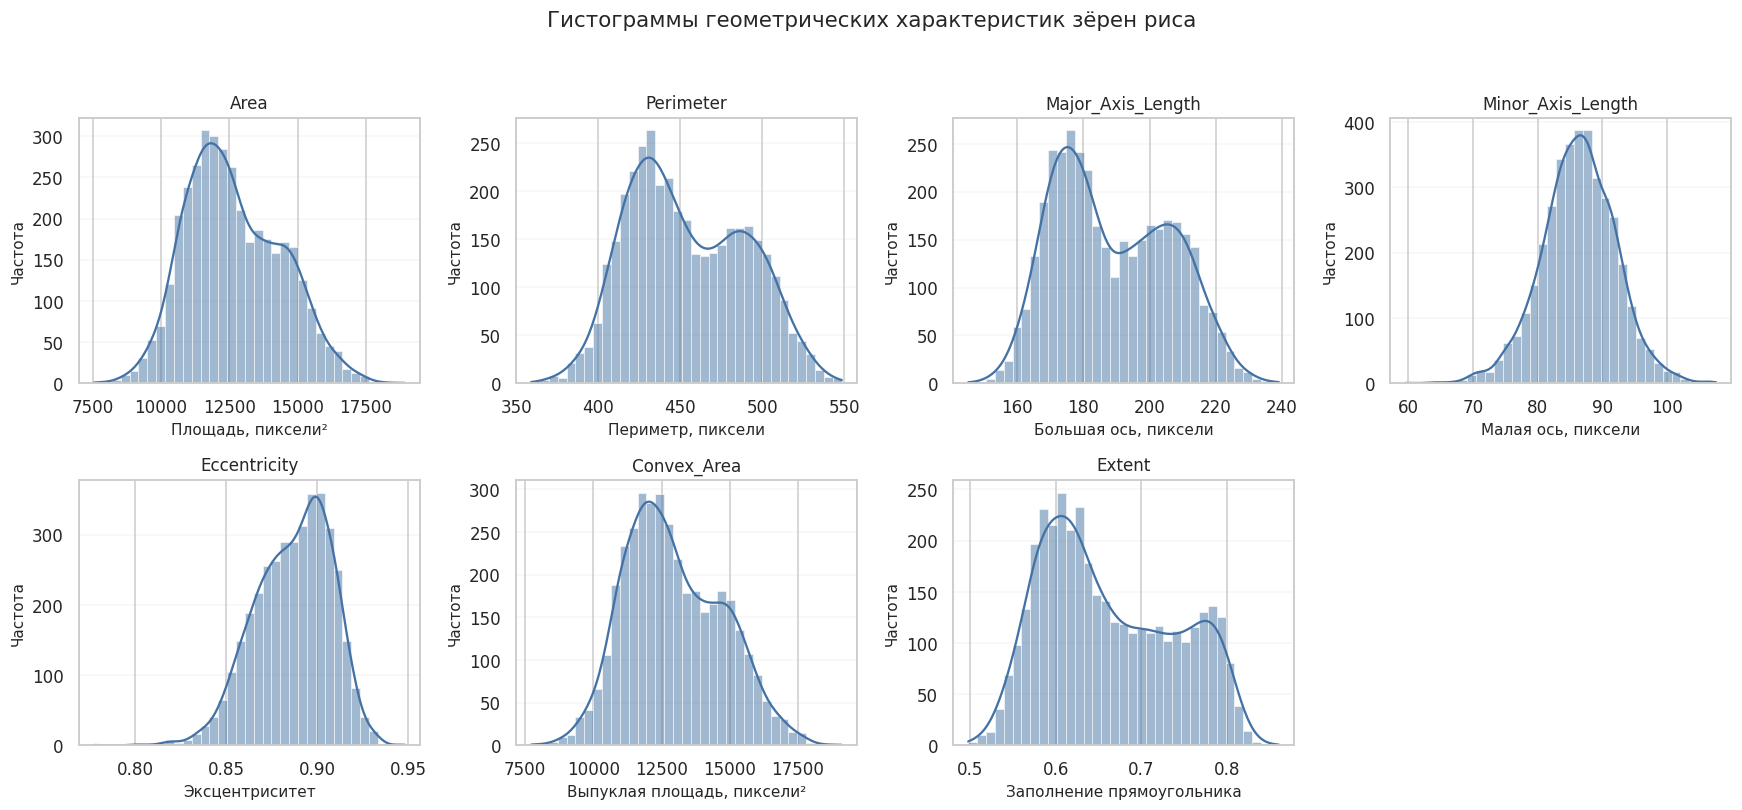

In [3]:
numeric_summary = df[ALL_NUMERIC].describe().T
numeric_summary["Skewness"] = df[ALL_NUMERIC].skew()
numeric_summary["Уникальных значений"] = df[ALL_NUMERIC].nunique()
print("Числовые характеристики всех семи исходных признаков:")
display(numeric_summary.round(3))

fig, axes = plt.subplots(2, 4, figsize=(16, 7.5))
for ax, col in zip(axes.flat, ALL_NUMERIC):
    sns.histplot(df[col], bins=35, kde=True, color="#4472a4", ax=ax,
                 edgecolor="white", linewidth=.35)
    ax.set_title(col)
    ax.set_xlabel(FEATURE_DESCRIPTIONS[col])
    ax.set_ylabel("Частота")
    ax.grid(axis="y", alpha=.18)
for ax in axes.flat[len(ALL_NUMERIC):]:
    ax.set_visible(False)
fig.suptitle("Гистограммы геометрических характеристик зёрен риса", fontsize=14)
fig.tight_layout(rect=[0, 0, 1, .95])
plt.show()

#### Вывод по распределениям

У большинства геометрических измерений коэффициент асимметрии сравнительно невелик (например, `Area`: **+0,325**, `Major_Axis_Length`: **+0,260**), а у `Eccentricity` асимметрия отрицательная (**−0,449**). Распределения не обязаны быть строго нормальными: визуально у некоторых признаков заметны неоднородность или несколько областей повышенной плотности. Различия масштабов (площадь измеряется тысячами пикселей², а `Eccentricity` — числами около 0,9) требуют стандартизации перед евклидовыми алгоритмами. `StandardScaler` выравнивает масштабы, **не превращая распределения в нормальные**.

### 2.6. Распределение известной категории `Class`

`Class` — единственная категориальная переменная, причём это **эталон сорта**, а не категориальный вход. Частоты приведены только для описания выборки; ни кодирование сорта, ни его баланс не используются для кластеризации или выбора `k`.

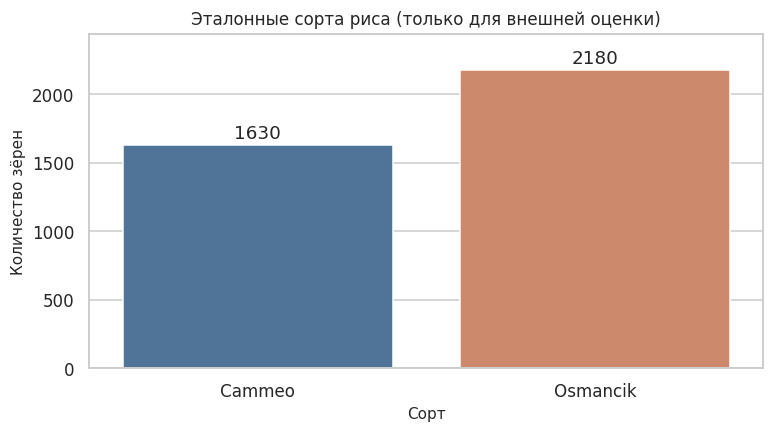

In [4]:
fig, ax = plt.subplots(figsize=(7.2, 4.1))
sns.countplot(data=df, x="Class", order=["Cammeo", "Osmancik"],
              hue="Class", legend=False, palette=["#4472a4", "#dd835b"], ax=ax)
ax.set_title("Эталонные сорта риса (только для внешней оценки)")
ax.set_xlabel("Сорт")
ax.set_ylabel("Количество зёрен")
for p in ax.patches:
    ax.annotate(f"{int(p.get_height())}",
                (p.get_x() + p.get_width()/2, p.get_height()),
                xytext=(0, 4), textcoords="offset points", ha="center")
ax.set_ylim(0, df["Class"].value_counts().max() * 1.12)
plt.tight_layout()
plt.show()

### 2.7. Оценка информационной значимости и избыточности признаков

Без использования `Class` невозможно рассчитывать «важность для предсказания сорта» и затем выдавать её за независимый анализ кластеризации. Для задачи без учителя оцениваем **вариативность**, число различных значений и **корреляционную избыточность**. Очень близкие признаки могут дважды усиливать один аспект геометрии в евклидовом расстоянии.

,Уникальных значений,Стандартное отклонение,"Доля уникальных значений, %"
Area,2828,1732.368,74.226
Perimeter,3738,35.597,98.110
Major_Axis_Length,3808,17.449,99.948
Minor_Axis_Length,3804,5.730,99.843
Eccentricity,3803,0.021,99.816
Convex_Area,2857,1776.972,74.987
Extent,3804,0.077,99.843


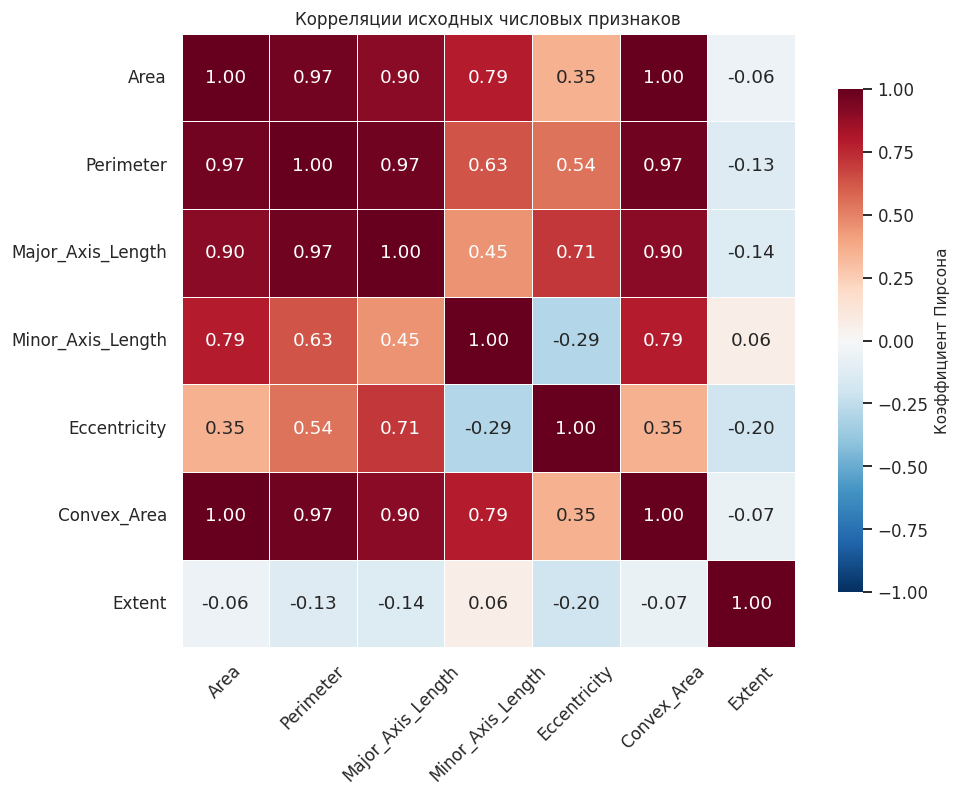

Пары с |r| ≥ 0.95:


,Признак 1,Признак 2,Корреляция
0,Area,Perimeter,0.9665
1,Area,Convex_Area,0.9989
2,Perimeter,Major_Axis_Length,0.9719
3,Perimeter,Convex_Area,0.9699


In [5]:
informativeness = pd.DataFrame({
    "Уникальных значений": df[ALL_NUMERIC].nunique(),
    "Стандартное отклонение": df[ALL_NUMERIC].std(),
    "Доля уникальных значений, %": 100 * df[ALL_NUMERIC].nunique() / len(df)
})
display(informativeness.round(3))

corr = df[ALL_NUMERIC].corr()
fig, ax = plt.subplots(figsize=(9.5, 7.4))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0,
            vmin=-1, vmax=1, square=True, linewidths=.45,
            cbar_kws={"label": "Коэффициент Пирсона", "shrink": .82}, ax=ax)
ax.set_title("Корреляции исходных числовых признаков")
ax.tick_params(axis="x", rotation=45)
ax.tick_params(axis="y", rotation=0)
fig.tight_layout()
plt.show()

correlated_pairs = [
    (a, b, round(corr.loc[a, b], 4))
    for a, b in combinations(ALL_NUMERIC, 2)
    if abs(corr.loc[a, b]) >= .95
]
print("Пары с |r| ≥ 0.95:")
display(pd.DataFrame(correlated_pairs, columns=["Признак 1", "Признак 2", "Корреляция"]))

#### Вывод по информативности

Почти все признаки имеют тысячи разных значений; исключение — `Area` (2828 различных измерений) и `Convex_Area` (2857), которые всё равно достаточно непрерывны для анализа. Но вариативность ещё не означает отсутствие избыточности: **корреляция `Area`–`Convex_Area` равна 0,9989**, а **`Perimeter`–`Major_Axis_Length` — 0,9719**. Для основной модели без обращения к `Class` выбраны **пять признаков**: `Area`, `Major_Axis_Length`, `Minor_Axis_Length`, `Eccentricity`, `Extent`. Удалены `Convex_Area` и `Perimeter`, чтобы не усиливать многократно одно и то же описание размера. Оставшиеся признаки тоже не полностью независимы, что нужно учитывать при интерпретации.

### 2.8. Проверка потенциальных выбросов по IQR

Для каждого исходного признака определим границы \(Q_1 - 1.5\,IQR\) и \(Q_3 + 1.5\,IQR\), где \(IQR=Q_3-Q_1\). Это **диагностическое правило**, а не основание автоматически удалять все необычные зёрна. По данным предметной области некоторые крайние значения отражают реальные формы.

,Q1,Q3,Нижняя граница,Верхняя граница,IQR-выбросов,"Доля, %"
Признак,,,,,,
Area,11370.500,13950.000,7501.250,17819.250,4,0.105
Perimeter,426.145,483.684,339.836,569.992,0,0.000
Major_Axis_Length,174.354,203.550,130.559,247.345,0,0.000
Minor_Axis_Length,82.732,90.144,71.614,101.262,65,1.706
Eccentricity,0.872,0.903,0.827,0.948,21,0.551
Convex_Area,11626.250,14284.000,7639.625,18270.625,3,0.079
Extent,0.599,0.727,0.407,0.918,0,0.000


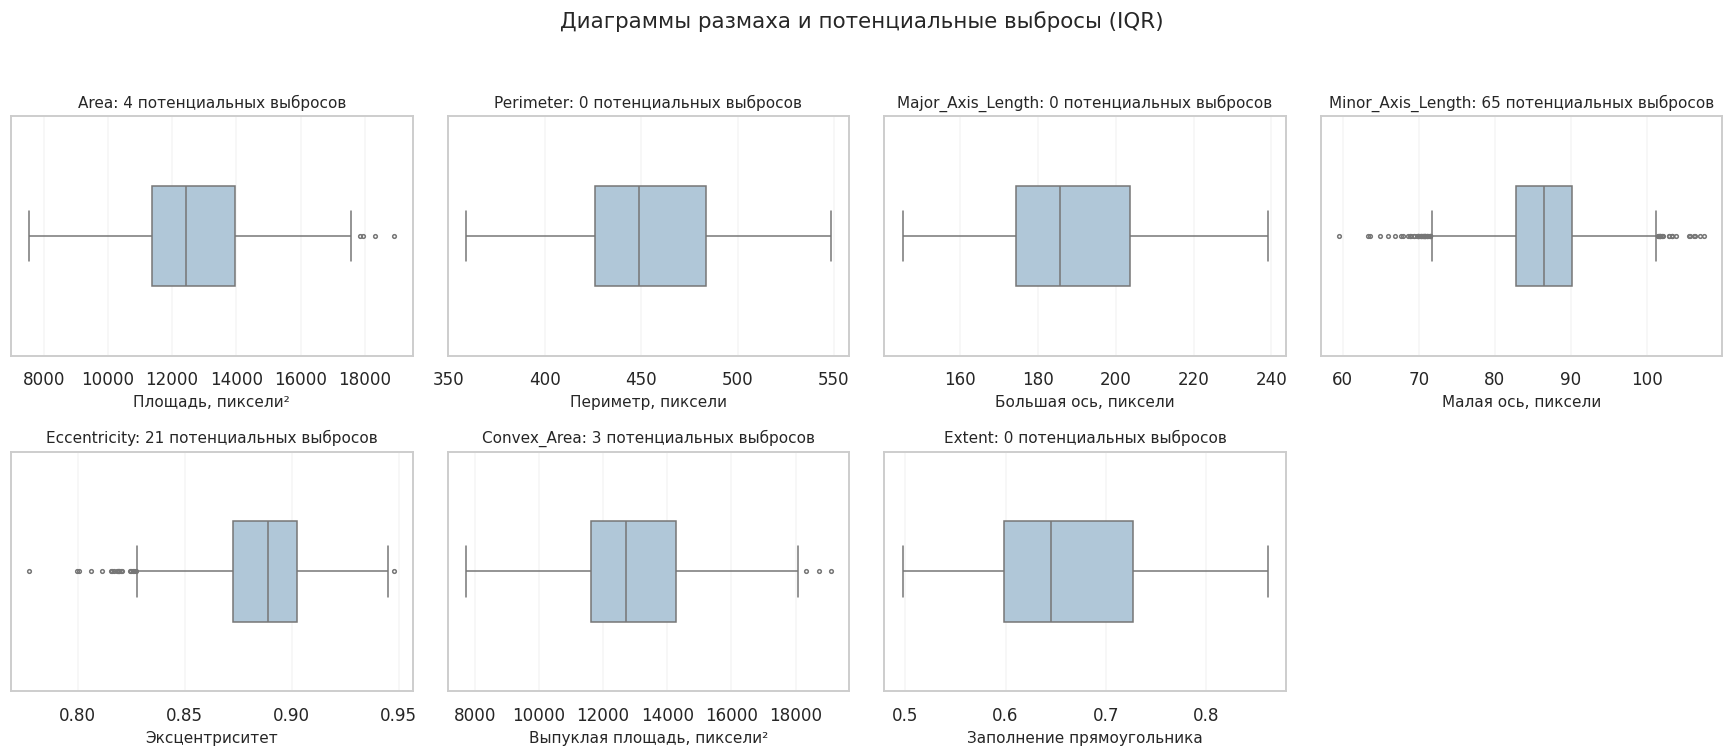

In [6]:
outlier_rows = []
outlier_masks = pd.DataFrame(index=df.index)
for col in ALL_NUMERIC:
    q1, q3 = df[col].quantile([.25, .75])
    iqr = q3 - q1
    lo, hi = q1 - 1.5*iqr, q3 + 1.5*iqr
    mask = (df[col] < lo) | (df[col] > hi)
    outlier_masks[col] = mask
    outlier_rows.append({"Признак": col, "Q1": q1, "Q3": q3,
                         "Нижняя граница": lo, "Верхняя граница": hi,
                         "IQR-выбросов": int(mask.sum()),
                         "Доля, %": 100*mask.mean()})
outlier_summary = pd.DataFrame(outlier_rows).set_index("Признак")
display(outlier_summary.round(3))

fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, col in zip(axes.flat, ALL_NUMERIC):
    sns.boxplot(x=df[col], ax=ax, color="#a9c8df", fliersize=2.4,
                width=.42, linewidth=1)
    ax.set_title(f"{col}: {outlier_masks[col].sum()} потенциальных выбросов", fontsize=10)
    ax.set_xlabel(FEATURE_DESCRIPTIONS[col])
    ax.grid(axis="x", alpha=.2)
for ax in axes.flat[len(ALL_NUMERIC):]:
    ax.set_visible(False)
fig.suptitle("Диаграммы размаха и потенциальные выбросы (IQR)", fontsize=14)
fig.tight_layout(rect=[0, 0, 1, .95])
plt.show()

#### Решение по выбросам

По IQR наиболее заметны крайние значения `Minor_Axis_Length` — **65 (1,71%)** и `Eccentricity` — **21 (0,55%)**. Среди пяти выбранных признаков **85 объектов (2,23%)** имеют хотя бы один IQR-флаг. Это небольшой процент, а признаки отражают реальные физические измерения зёрен; оснований считать крайние значения ошибками нет. **Не удаляем строки и не ограничиваем квантили** — все **3810 объектов** сохраняются. При интерпретации K-means учитываем его чувствительность к крайним измерениям.

### 2.9. Проверка условий применимости кластеризации

Предметная область позволяет осмысленно трактовать найденные группы по геометрии. Данные числовые и чистые, а классы при обучении отсутствуют: сорт `Class` отделяется от входа. Проверены выбросы и высокая корреляция геометрических измерений. Гипотеза: зёрна разных размеров и форм могут образовывать относительно компактные группы, однако перекрытие в отдельных проекциях допустимо. Метод K-means предполагает компактные группы вокруг центров; Ward строит иерархию, минимизируя увеличение внутрикластерного разброса.

In [7]:
y_external = df["Class"].copy()   # Только для внешней проверки
X_candidate = df[ALL_NUMERIC].copy()
assert "Class" not in X_candidate.columns
print("Размер матрицы без меток класса:", X_candidate.shape)
print("Известные классы хранятся отдельно:", sorted(y_external.unique()))

Размер матрицы без меток класса: (3810, 7)
Известные классы хранятся отдельно: ['Cammeo', 'Osmancik']


#### Вывод о пригодности

Набор подходит для **обучения без учителя**, если `Class` полностью исключён из признакового пространства и не используется при выборе параметров. Внешние метрики будут рассчитаны только после получения кластеров. Результаты нельзя считать точной классификацией двух сортов: кластер — группа близких измерений, а не автоматически правильный сорт.

## 3. Предобработка данных
### 3.1. Формирование матрицы признаков

В кластеризацию идут пять заранее отобранных геометрических признаков. Два наиболее избыточных измерения (`Perimeter`, `Convex_Area`) исключены. Известная метка `Class` также исключена. Все данные остаются в исходных единицах для последующей интерпретации профилей.

In [8]:
selected_features = ["Area", "Major_Axis_Length", "Minor_Axis_Length",
                     "Eccentricity", "Extent"]
excluded_features = [c for c in ALL_NUMERIC if c not in selected_features]
X_raw = df[selected_features].copy()
assert "Class" not in selected_features
assert len(X_raw) == len(y_external) == len(df)
print("Включены:", selected_features)
print("Исключены как избыточные:", excluded_features)
print("Число объектов, число признаков:", X_raw.shape)
display(X_raw.head())

Включены: ['Area', 'Major_Axis_Length', 'Minor_Axis_Length', 'Eccentricity', 'Extent']
Исключены как избыточные: ['Perimeter', 'Convex_Area']
Число объектов, число признаков: (3810, 5)


,Area,Major_Axis_Length,Minor_Axis_Length,Eccentricity,Extent
0,15231.0,229.749878,85.093788,0.928882,0.572896
1,14656.0,206.020065,91.730972,0.895405,0.615436
2,14634.0,214.106781,87.768288,0.912118,0.693259
3,13176.0,193.337387,87.448395,0.891861,0.640669
4,14688.0,211.743378,89.312454,0.906691,0.646024


### 3.2. Решение об обработке экстремальных значений

После IQR-диагностики **не удаляем строки и не заменяем крайние значения**, потому что признаки представляют реальные физические измерения, а не ошибки регистрации. Результаты до и после этапа должны содержать одинаковое число объектов. Такая обработка не подглядывает в эталонные метки и позволяет объективно оценить качество кластеризации на полном наборе.

In [9]:
assert len(X_raw) == 3810
outlier_summary_selected = outlier_summary.loc[selected_features, ["IQR-выбросов", "Доля, %"]]
print("Потенциальные IQR-выбросы в отобранных признаках:")
display(outlier_summary_selected.round(2))
objects_with_outliers = int(outlier_masks[selected_features].any(axis=1).sum())
print(f"Объектов с хотя бы одним IQR-флагом: {objects_with_outliers} "
      f"({100*objects_with_outliers/len(df):.2f}%)")
print("Объектов сохранено в X_raw:", len(X_raw))

Потенциальные IQR-выбросы в отобранных признаках:


,IQR-выбросов,"Доля, %"
Признак,,
Area,4,0.10
Major_Axis_Length,0,0.00
Minor_Axis_Length,65,1.71
Eccentricity,21,0.55
Extent,0,0.00


Объектов с хотя бы одним IQR-флагом: 85 (2.23%)
Объектов сохранено в X_raw: 3810


### 3.3. Стандартизация

Масштабы разных геометрических величин существенно различаются: площадь измеряется тысячами пикселей², эксцентриситет и `Extent` лежат примерно в интервале от 0 до 1. Для евклидовых методов выбран **`StandardScaler`**: среднее каждого признака становится близким к нулю, стандартное отклонение — к единице. Кодирование категорий не требуется: `Class` не участвует в кластеризации. В этой работе исследуется структура всей выборки, **обучающего/тестового разбиения нет**.

In [10]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_raw)
scaled_df = pd.DataFrame(X_scaled, columns=selected_features, index=df.index)
print("Размер матрицы после стандартизации:", X_scaled.shape)
display(pd.DataFrame({"Среднее": scaled_df.mean(),
                      "Стандартное отклонение (ddof=0)": scaled_df.std(ddof=0)}).round(5))
assert np.allclose(scaled_df.mean().to_numpy(), 0, atol=1e-10)
assert np.allclose(scaled_df.std(ddof=0).to_numpy(), 1, atol=1e-10)
assert np.isfinite(X_scaled).all()

Размер матрицы после стандартизации: (3810, 5)


,Среднее,Стандартное отклонение (ddof=0)
Area,0.0,1.0
Major_Axis_Length,0.0,1.0
Minor_Axis_Length,-0.0,1.0
Eccentricity,0.0,1.0
Extent,-0.0,1.0


#### Вывод по предобработке

Для кластеризации получена матрица **3810 × 5** без сортовых меток и пропусков. После `StandardScaler` признаки сопоставимы по масштабу. Преобразование изменяет масштабы, **но не устраняет** корреляции, выбросы или ненормальность исходных распределений. Обратное преобразование центров позволит интерпретировать результаты в физических единицах.

### 3.4. Матрица диаграмм рассеивания

Для визуальной оценки формы облаков используем четыре разных геометрических признака: `Area`, `Minor_Axis_Length`, `Eccentricity`, `Extent`. Диаграмма строится **без раскраски по `Class`**, чтобы избежать подсказки истинных сортов при выборе структуры. Ради читаемости показывается воспроизводимая выборка из 1200 строк, при этом **все 3810 объектов участвуют в кластеризации**. Масштаб — стандартизированный.

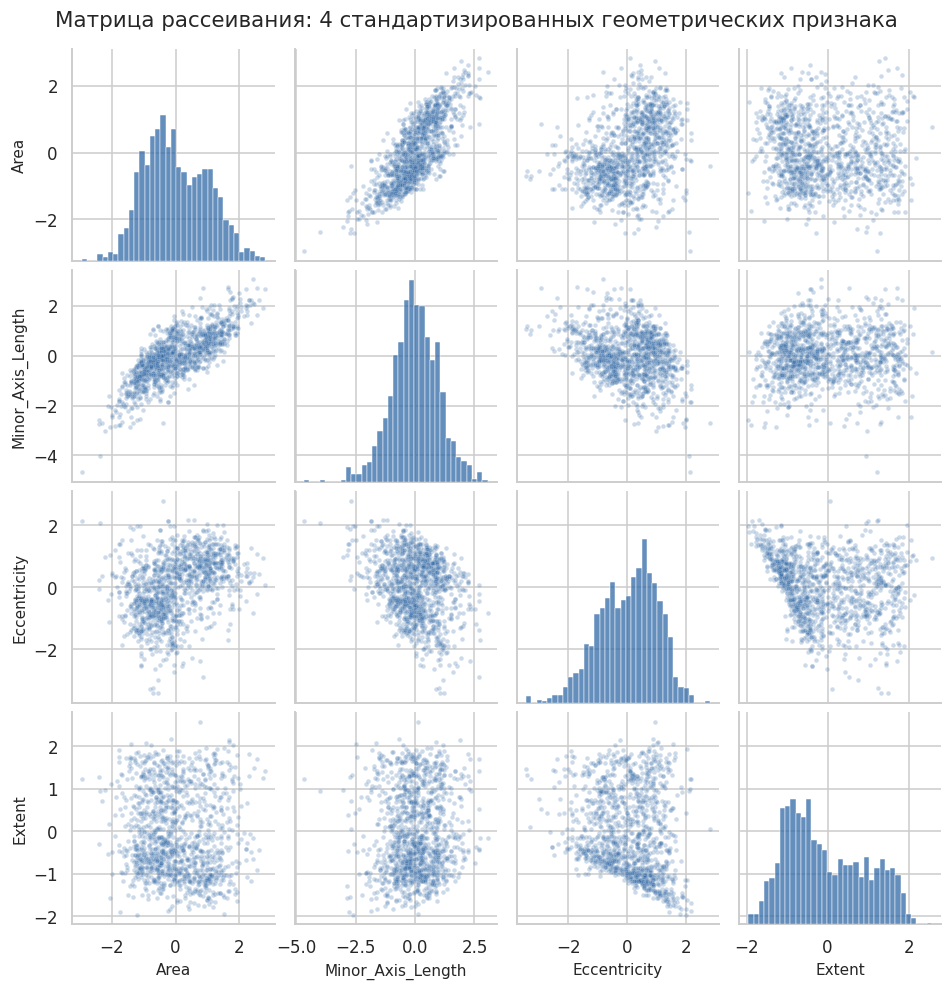

In [11]:
pair_features = ["Area", "Minor_Axis_Length", "Eccentricity", "Extent"]
pairplot_data = scaled_df[pair_features].sample(n=1200, random_state=RANDOM_STATE)
g = sns.pairplot(pairplot_data, diag_kind="hist", corner=False,
                 plot_kws={"s": 9, "alpha": .25, "color": "#3068a6", "rasterized": True},
                 diag_kws={"bins": 35, "color": "#3068a6", "edgecolor": None},
                 height=2.2, aspect=1)
g.figure.suptitle("Матрица рассеивания: 4 стандартизированных геометрических признака",
                  fontsize=14, y=1.02)
plt.show()

#### Вывод по матрице диаграмм рассеивания

Непрерывные геометрические измерения образуют облака точек без доминирования одной или двух координат. На парах `Area`–`Minor_Axis_Length` заметна положительная связь, `Eccentricity`–`Minor_Axis_Length` — обратная, а `Extent` отличается по форме распределения. Массовых вертикальных полос из-за одного доминирующего значения нет. В то же время жёсткой границы между несколькими группами на каждом двумерном графике не видно — возможны перекрытия. С учётом формы облаков разумно сравнить K-means и Ward на полной пятимерной стандартизированной матрице; `k` уточним по метрикам и дендрограмме без использования сортов.

## 4. Подбор количества кластеров
### 4.1. Метод локтя и силуэтный анализ K-means

Проверяем `k` от **2 до 8**, задаём `init='k-means++'`, `n_init=10`, `tol=1e-8` (точная сходимость центров), `random_state=42`. Инерция — сумма квадратов расстояний до центров (уменьшается при росте `k`). Силуэт — относительная разница меж- и внутрикластерных расстояний (**выше лучше**). Для повторяющихся проверок силуэт оценивается на фиксированной воспроизводимой подвыборке из 1200 объектов (параметр `sample_size`), остальные метрики — на полной матрице. Окончательные метрики двух выбранных моделей ниже считаются по всем 3810 наблюдениям.

,Inertia,Silhouette,Calinski-Harabasz,Davies-Bouldin,Размеры кластеров
k,,,,,
2,11655.5677,0.3527,2415.8410,1.1440,"[2188, 1622]"
3,9216.5977,0.2918,2030.8884,1.2182,"[1433, 1308, 1069]"
4,7851.1592,0.2773,1809.6176,1.2944,"[1226, 984, 981, 619]"
5,6899.6998,0.2707,1675.1414,1.2520,"[958, 927, 754, 586, 585]"
6,6053.4547,0.2545,1633.4097,1.1481,"[843, 665, 616, 609, 572, 505]"
7,5447.6819,0.2594,1582.6186,1.1316,"[758, 625, 592, 540, 493, 469, 333]"
8,4976.2698,0.2572,1536.0996,1.0996,"[725, 589, 522, 463, 446, 377, 344, 344]"


Наибольший выборочный силуэт K-means при k = 2


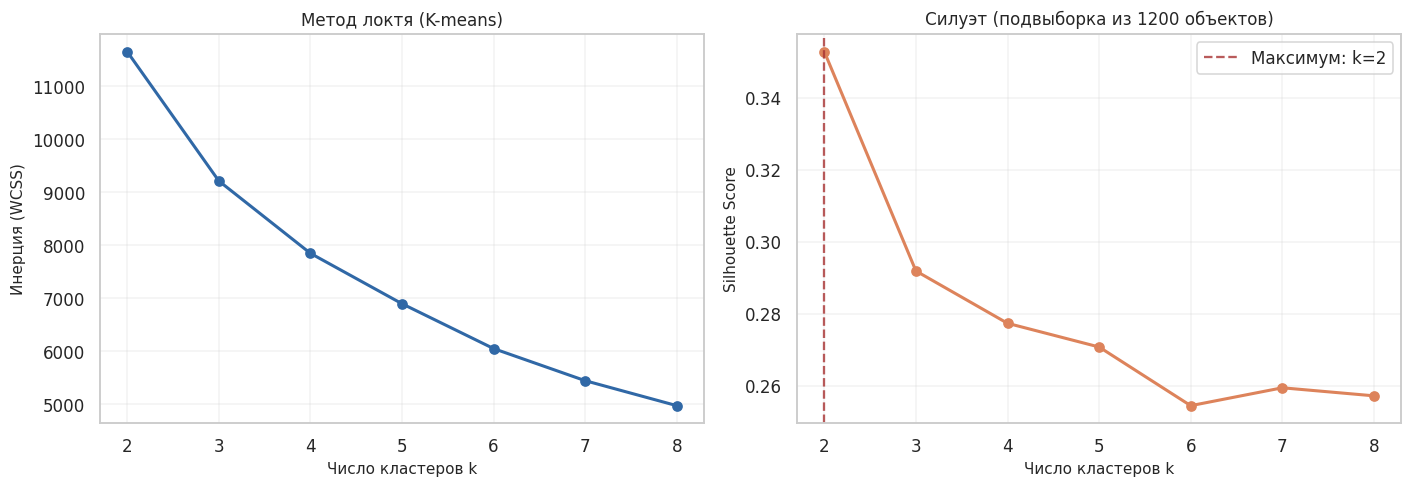

In [12]:
K_VALUES = list(range(2, 9))
SIL_SAMPLE = 1200
kmeans_search_rows = []
for k in K_VALUES:
    model = KMeans(n_clusters=k, init="k-means++", n_init=10, tol=1e-8, max_iter=500,
                   random_state=RANDOM_STATE)
    labels = model.fit_predict(X_scaled)
    kmeans_search_rows.append({
        "k": k, "Inertia": model.inertia_,
        "Silhouette": silhouette_score(X_scaled, labels, sample_size=SIL_SAMPLE,
                                       random_state=RANDOM_STATE),
        "Calinski-Harabasz": calinski_harabasz_score(X_scaled, labels),
        "Davies-Bouldin": davies_bouldin_score(X_scaled, labels),
        "Размеры кластеров": sorted(np.bincount(labels).tolist(), reverse=True)
    })
kmeans_search_df = pd.DataFrame(kmeans_search_rows).set_index("k")
display(kmeans_search_df.round(4))
best_k_kmeans = int(kmeans_search_df["Silhouette"].idxmax())
print("Наибольший выборочный силуэт K-means при k =", best_k_kmeans)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
axes[0].plot(kmeans_search_df.index, kmeans_search_df["Inertia"],
             marker="o", linewidth=2, color="#3068a6")
axes[0].set_title("Метод локтя (K-means)")
axes[0].set_ylabel("Инерция (WCSS)")
axes[1].plot(kmeans_search_df.index, kmeans_search_df["Silhouette"],
             marker="o", linewidth=2, color="#dd835b")
axes[1].axvline(best_k_kmeans, color="#a83232", linestyle="--",
                alpha=.8, label=f"Максимум: k={best_k_kmeans}")
axes[1].set_title("Силуэт (подвыборка из 1200 объектов)")
axes[1].set_ylabel("Silhouette Score")
axes[1].legend()
for ax in axes:
    ax.set_xticks(K_VALUES)
    ax.set_xlabel("Число кластеров k")
    ax.grid(alpha=.25)
fig.tight_layout()
plt.show()

#### Вывод по выбору `k` для K-means

Выборочный Silhouette достигает максимума при **`k=2` (0,3527)**; при `k=3` снижается до **0,2918**. Инерция уменьшается с **11655,6** (`k=2`) до **9216,6** (`k=3`) и далее монотонно убывает, но это само по себе не аргумент в пользу большего числа групп. Форма локтя допускает интерпретацию небольшого числа кластеров; максимум силуэта обосновывает выбор **двух**. Известные сорта на этом шаге не использовались.

### 4.2. Дендрограмма иерархической кластеризации

Для Ward используется евклидово расстояние и минимальное увеличение внутрикластерной суммы квадратов. Полное дерево на 3810 объектов строим для отбора `k`, но отрисовывать 3810 подписей неинформативно: показываем **укороченную дендрограмму полного дерева** с последними 20 слияниями и размерами поддеревьев. Дополнительно строим более подробную дендрограмму воспроизводимой подвыборки из 240 зёрен. Число кластеров выбираем не только по высотам слияний, но и по силуэту.

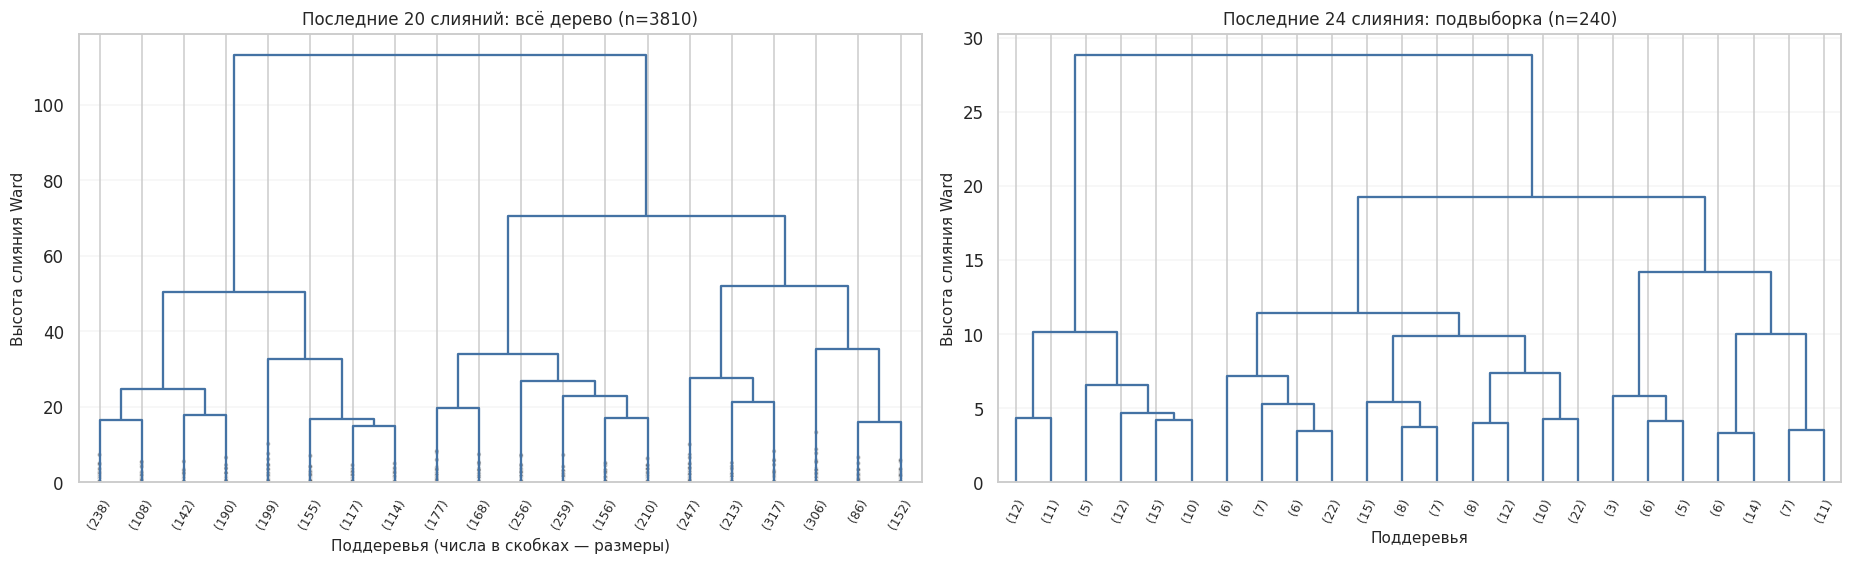

In [13]:
# Полное дерево для исследования разных k — без повторного запуска n раз.
full_tree = linkage(X_scaled, method="ward", metric="euclidean", optimal_ordering=False)

rng = np.random.default_rng(RANDOM_STATE)
dendro_ids = np.sort(rng.choice(len(df), size=240, replace=False))
sample_tree = linkage(X_scaled[dendro_ids], method="ward", metric="euclidean")

fig, axes = plt.subplots(1, 2, figsize=(17, 5.3))
dendrogram(full_tree, truncate_mode="lastp", p=20, show_leaf_counts=True,
           show_contracted=True, leaf_rotation=60, leaf_font_size=8,
           color_threshold=0, above_threshold_color="#4472a4", ax=axes[0])
axes[0].set_title("Последние 20 слияний: всё дерево (n=3810)")
axes[0].set_xlabel("Поддеревья (числа в скобках — размеры)")
axes[0].set_ylabel("Высота слияния Ward")
dendrogram(sample_tree, truncate_mode="lastp", p=24, show_leaf_counts=True,
           leaf_rotation=65, leaf_font_size=8,
           color_threshold=0, above_threshold_color="#4472a4", ax=axes[1])
axes[1].set_title("Последние 24 слияния: подвыборка (n=240)")
axes[1].set_xlabel("Поддеревья")
axes[1].set_ylabel("Высота слияния Ward")
for ax in axes:
    ax.grid(axis="y", alpha=.2)
fig.tight_layout()
plt.show()

#### Вывод по дендрограмме

На полном дереве Ward (3810 объектов) верхнее слияние происходит примерно на высоте **113**, заметно выше следующего крупного слияния (около **71**). Это согласуется с гипотезой о двух крупных группах. Для читаемости показаны последние 20 слияний **полного** дерева и 24 последних слияния дерева случайной подвыборки из 240 зёрен; подписи не перегружены. Для подтверждения числа кластеров используем силуэт по всему набору, а не одну лишь дендрограмму.

### 4.3. Подбор `k` для иерархической кластеризации Ward

Для каждого `k=2…8` «разрежем» **одно и то же полное дерево** функцией `cut_tree`. Это эквивалентно Ward-разбиению на `k` групп, но существенно экономит время по сравнению с полным перестроением дерева семь раз. Итоговая модель `AgglomerativeClustering` будет создана и запущена отдельно в разделе 5.2. Подбор снова делаем только по внутренним метрикам, используя одинаковую схему выборки для силуэта.

,Silhouette,Calinski-Harabasz,Davies-Bouldin,Размеры кластеров
k,,,,
2,0.3109,1925.6077,1.2040,"[2547, 1263]"
3,0.2378,1666.2341,1.3843,"[1321, 1263, 1226]"
4,0.2089,1475.7293,1.3250,"[1263, 1226, 777, 544]"
5,0.2255,1452.2479,1.2717,"[1226, 777, 678, 585, 544]"
6,0.2176,1335.5287,1.1403,"[1226, 777, 678, 585, 306, 238]"
7,0.2082,1270.6998,1.2793,"[881, 777, 678, 585, 345, 306, 238]"
8,0.2036,1238.8660,1.2087,"[881, 777, 678, 386, 345, 306, 238, 199]"


Наибольший выборочный силуэт Ward при k = 2


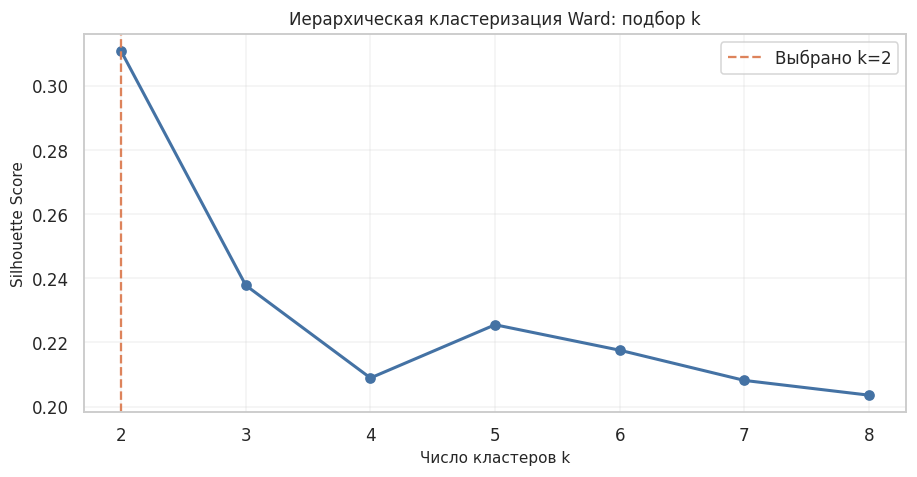

In [14]:
agg_search_rows = []
for k in K_VALUES:
    labels = cut_tree(full_tree, n_clusters=k).reshape(-1)
    agg_search_rows.append({
        "k": k,
        "Silhouette": silhouette_score(X_scaled, labels, sample_size=SIL_SAMPLE,
                                       random_state=RANDOM_STATE),
        "Calinski-Harabasz": calinski_harabasz_score(X_scaled, labels),
        "Davies-Bouldin": davies_bouldin_score(X_scaled, labels),
        "Размеры кластеров": sorted(pd.Series(labels).value_counts().tolist(), reverse=True)
    })
agglomerative_search_df = pd.DataFrame(agg_search_rows).set_index("k")
display(agglomerative_search_df.round(4))
best_k_agglomerative = int(agglomerative_search_df["Silhouette"].idxmax())
print("Наибольший выборочный силуэт Ward при k =", best_k_agglomerative)

fig, ax = plt.subplots(figsize=(8.5, 4.5))
ax.plot(agglomerative_search_df.index, agglomerative_search_df["Silhouette"],
        marker="o", linewidth=2, color="#4472a4")
ax.axvline(best_k_agglomerative, ls="--", color="#dd835b",
           label=f"Выбрано k={best_k_agglomerative}")
ax.set(xlabel="Число кластеров k", ylabel="Silhouette Score",
       title="Иерархическая кластеризация Ward: подбор k")
ax.set_xticks(K_VALUES)
ax.legend()
ax.grid(alpha=.25)
fig.tight_layout()
plt.show()

#### Вывод по подбору `k` для Ward

Для Ward максимальный выборочный силуэт тоже получается при **`k=2` (0,3109)**; для `k=3` он падает до **0,2378**. Это согласуется с наиболее крупным скачком высоты на дендрограмме. Поэтому итоговая иерархическая модель обучается с **`n_clusters=2`** на всех 3810 объектах.

## 5. Реализация алгоритмов кластеризации
### 5.1. K-means

`n_clusters` — выбранное в разделе 4 число групп; `init='k-means++'` — инициализация центров; `n_init=10`, `tol=1e-8` (точная сходимость центров) — 10 перезапусков для устойчивости; `random_state=42` — воспроизводимость. Вычисляем метки, размеры, центры и инерцию по стандартизированным данным.

In [15]:
kmeans_model = KMeans(n_clusters=best_k_kmeans, init="k-means++",
                      n_init=10, tol=1e-8, max_iter=500,
                      random_state=RANDOM_STATE)
kmeans_labels = kmeans_model.fit_predict(X_scaled)
print("K-means: k =", len(np.unique(kmeans_labels)))
print("Размеры:", pd.Series(kmeans_labels).value_counts().sort_index().to_dict())
print("Inertia:", round(kmeans_model.inertia_, 3))
assert len(kmeans_labels) == len(X_scaled)

K-means: k = 2
Размеры: {0: 1622, 1: 2188}
Inertia: 11655.568


### 5.2. Agglomerative Clustering (Ward)

Задаём `n_clusters`, `linkage='ward'`, `metric='euclidean'`. Метод не возвращает собственные центры, поэтому далее они вычисляются как средние векторы объектов внутри полученных групп. Номер метки кластера условен и не равен сорту.

In [16]:
agglomerative_model = AgglomerativeClustering(
    n_clusters=best_k_agglomerative, linkage="ward", metric="euclidean"
)
agglomerative_labels = agglomerative_model.fit_predict(X_scaled)
print("Ward: k =", len(np.unique(agglomerative_labels)))
print("Размеры:", pd.Series(agglomerative_labels).value_counts().sort_index().to_dict())
assert len(agglomerative_labels) == len(X_scaled)
# Проверяем совпадение разбиения Agglomerative и среза дерева (метки могут переставляться).
ward_cut_labels = cut_tree(full_tree, n_clusters=best_k_agglomerative).reshape(-1)
assert np.isclose(adjusted_rand_score(ward_cut_labels, agglomerative_labels), 1.0)

Ward: k = 2
Размеры: {0: 2547, 1: 1263}


## 6. Оценка качества кластеризации
### 6.1. Внутренние метрики

Рассчитываем метрики на **всех 3810 строках**: **Silhouette** (↑ лучше), **Calinski–Harabasz** (↑ лучше), **Davies–Bouldin** (↓ лучше). Если алгоритм выделяет лишь одну группу либо все объекты становятся шумом, внутренние показатели не определены — функция возвращает `NaN`. В данном исследовании K-means и Ward, поэтому шума с меткой −1 нет.

In [17]:
def calculate_internal_metrics(X, labels):
    """Внутренние метрики без шума; одна группа -> NaN."""
    labels = np.asarray(labels)
    keep = labels != -1
    X_valid, y_valid = X[keep], labels[keep]
    n_clusters = np.unique(y_valid).size
    if n_clusters < 2 or n_clusters >= len(y_valid):
        return {"Silhouette": np.nan, "Calinski-Harabasz": np.nan,
                "Davies-Bouldin": np.nan}
    return {
        "Silhouette": silhouette_score(X_valid, y_valid),  # Точное по всей выборке
        "Calinski-Harabasz": calinski_harabasz_score(X_valid, y_valid),
        "Davies-Bouldin": davies_bouldin_score(X_valid, y_valid)
    }

kmeans_metrics = calculate_internal_metrics(X_scaled, kmeans_labels)
agglomerative_metrics = calculate_internal_metrics(X_scaled, agglomerative_labels)
internal_comparison = pd.DataFrame({
    "K-means": kmeans_metrics,
    "Agglomerative (Ward)": agglomerative_metrics
}).T
print("Итоговые внутренние метрики (полная выборка):")
display(internal_comparison.round(4))

Итоговые внутренние метрики (полная выборка):


,Silhouette,Calinski-Harabasz,Davies-Bouldin
K-means,0.3523,2415.8410,1.144
Agglomerative (Ward),0.3142,1925.6077,1.204


### 6.2. Центры, компактность и расстояния

Центр кластера — средний вектор его объектов в стандартизированном пространстве. **Компактность** — среднее евклидово расстояние объектов до собственного центра; дополнительно рассчитываем среднее **квадратичное** расстояние и внутрикластерную сумму квадратов (`WCSS`). Межкластерные расстояния — евклидовы расстояния между центрами. Для Ward центры рассчитываются вручную, для K-means сверяются с `cluster_centers_`. Эти показатели зависят от выбранных пяти признаков.

In [18]:
def calculate_centroids(X, labels):
    """Массив центров и отсортированных ID кластеров; шум (-1) исключается."""
    cluster_ids = np.array(sorted(c for c in np.unique(labels) if c != -1))
    centers = np.vstack([X[np.asarray(labels) == c].mean(axis=0) for c in cluster_ids])
    return centers, cluster_ids


def cluster_compactness(X, labels, centers, cluster_ids):
    rows = []
    for center, c in zip(centers, cluster_ids):
        points = X[np.asarray(labels) == c]
        d = np.linalg.norm(points - center, axis=1)
        rows.append({"Кластер": int(c), "Количество": len(d),
                     "Среднее расстояние": d.mean(),
                     "Медиана расстояния": np.median(d),
                     "Среднее расстояние²": np.mean(d**2),
                     "WCSS": np.sum(d**2)})
    return pd.DataFrame(rows).set_index("Кластер")

kmeans_centroids, kmeans_cluster_ids = calculate_centroids(X_scaled, kmeans_labels)
agg_centroids, agg_cluster_ids = calculate_centroids(X_scaled, agglomerative_labels)
assert np.allclose(kmeans_centroids, kmeans_model.cluster_centers_, atol=1e-6)

kmeans_compactness = cluster_compactness(X_scaled, kmeans_labels,
                                         kmeans_centroids, kmeans_cluster_ids)
agg_compactness = cluster_compactness(X_scaled, agglomerative_labels,
                                      agg_centroids, agg_cluster_ids)
print("Компактность K-means (в стандартизированных координатах):")
display(kmeans_compactness.round(3))
print("Компактность Ward:")
display(agg_compactness.round(3))
print("Сумма WCSS K-means:", round(kmeans_compactness["WCSS"].sum(), 3),
      "; model.inertia_:", round(kmeans_model.inertia_, 3))
assert np.isclose(kmeans_compactness["WCSS"].sum(), kmeans_model.inertia_)

for name, centers, cluster_ids in [
    ("K-means", kmeans_centroids, kmeans_cluster_ids),
    ("Ward", agg_centroids, agg_cluster_ids)
]:
    distance_matrix = pd.DataFrame(pairwise_distances(centers),
                                    index=[f"Кластер {i}" for i in cluster_ids],
                                    columns=[f"Кластер {i}" for i in cluster_ids])
    print(f"Межцентровые расстояния: {name} (StandardScaler):")
    display(distance_matrix.round(3))

kmeans_centers_original = pd.DataFrame(scaler.inverse_transform(kmeans_centroids),
                                      columns=selected_features,
                                      index=[f"Кластер {i}" for i in kmeans_cluster_ids])
agg_centers_original = pd.DataFrame(scaler.inverse_transform(agg_centroids),
                                   columns=selected_features,
                                   index=[f"Кластер {i}" for i in agg_cluster_ids])
print("Центры K-means (исходные единицы):")
display(kmeans_centers_original.round(3))
print("Центры Ward (исходные единицы):")
display(agg_centers_original.round(3))

Компактность K-means (в стандартизированных координатах):


,Количество,Среднее расстояние,Медиана расстояния,Среднее расстояние²,WCSS
Кластер,,,,,
0,1622,1.604,1.537,2.992,4852.989
1,2188,1.619,1.522,3.109,6802.579


Компактность Ward:


,Количество,Среднее расстояние,Медиана расстояния,Среднее расстояние²,WCSS
Кластер,,,,,
0,2547,1.727,1.652,3.533,8997.453
1,1263,1.588,1.562,2.894,3654.686


Сумма WCSS K-means: 11655.568 ; model.inertia_: 11655.568
Межцентровые расстояния: K-means (StandardScaler):


,Кластер 0,Кластер 1
Кластер 0,0.000,2.818
Кластер 1,2.818,0.000


... (2 outputs left out)

Центры K-means (исходные единицы):


,Area,Major_Axis_Length,Minor_Axis_Length,Eccentricity,Extent
Кластер 0,14292.035,206.248,89.285,0.901,0.648
Кластер 1,11463.602,175.824,84.111,0.877,0.672


Центры Ward (исходные единицы):


,Area,Major_Axis_Length,Minor_Axis_Length,Eccentricity,Extent
Кластер 0,11727.032,178.990,84.493,0.880,0.659
Кластер 1,14564.759,208.512,89.986,0.901,0.668


#### Вывод по центрам и расстояниям

При `k=2` межцентровое расстояние в стандартизированном пространстве составляет примерно **2,818** для K-means и **2,753** для Ward. Компактность K-means: средние расстояния объектов до своих центров около **1,604** и **1,619**; у Ward — **1,727** и **1,588**. Сумма квадратов расстояний K-means (**11655,568**) совпадает с `inertia_`. Ward формирует группы с другой границей и более неравными размерами, поэтому его суммарные и средние расстояния отличаются. Числа на этом этапе относятся к стандартизированным координатам, а физический смысл раскрывают центры после `inverse_transform`.

### 6.3. Внешние метрики (по известным сортам, только после кластеризации)

Теперь сопоставим результаты с отложенным `Class` без обучения на нём: **ARI** (скорректированный индекс Рэнда), **Rand Index**, **NMI**, **Homogeneity**, **Completeness**, **V-measure**. Дополнительно рассчитаем **попарный Jaccard**: долю пар, попавших вместе и в эталоне, и в кластеризации, среди пар, связанных хотя бы одним из двух разбиений. Для этих метрик **номера кластеров произвольны**: перестановка ID на результат не влияет.

In [19]:
# Эталон не участвовал ни в подборе признаков, ни в стандартизации, ни в выборе k.
y_true = y_external.to_numpy()

def pairwise_jaccard_partition(y_ref, y_pred):
    """Jaccard для пар объектов: инвариантен к перенумерации кластеров."""
    contingency = pd.crosstab(pd.Series(y_ref, name="ref"),
                              pd.Series(y_pred, name="pred")).to_numpy(dtype=np.int64)
    choose2 = lambda z: np.asarray(z, dtype=np.float64) * (np.asarray(z) - 1) / 2
    tp = choose2(contingency).sum()
    ref_pairs = choose2(contingency.sum(axis=1)).sum()
    pred_pairs = choose2(contingency.sum(axis=0)).sum()
    denom = ref_pairs + pred_pairs - tp
    return tp / denom if denom else np.nan

external_rows = []
for method_name, labels in [
    ("K-means", kmeans_labels),
    ("Agglomerative (Ward)", agglomerative_labels)
]:
    external_rows.append({
        "Метод": method_name,
        "ARI": adjusted_rand_score(y_true, labels),
        "Rand": rand_score(y_true, labels),
        "Jaccard (pairs)": pairwise_jaccard_partition(y_true, labels),
        "NMI": normalized_mutual_info_score(y_true, labels),
        "Homogeneity": homogeneity_score(y_true, labels),
        "Completeness": completeness_score(y_true, labels),
        "V-measure": v_measure_score(y_true, labels)
    })
external_comparison = pd.DataFrame(external_rows).set_index("Метод")
display(external_comparison.round(4))

for method_name, labels in [("K-means", kmeans_labels),
                             ("Ward", agglomerative_labels)]:
    table = pd.crosstab(pd.Series(labels, name="Найденный кластер"),
                        pd.Series(y_true, name="Эталонный сорт"))
    print(f"Таблица сопряжённости: {method_name} (объектов)")
    display(table)
    print("Доля каждого сорта внутри кластера, %:")
    display((100*table.div(table.sum(axis=1), axis=0)).round(2))

,ARI,Rand,Jaccard (pairs),NMI,Homogeneity,Completeness,V-measure
Метод,,,,,,,
K-means,0.6991,0.8496,0.7432,0.5862,0.5859,0.5865,0.5862
Agglomerative (Ward),0.5251,0.7631,0.6366,0.4494,0.4338,0.4662,0.4494


Таблица сопряжённости: K-means (объектов)


Эталонный сорт,Cammeo,Osmancik
Найденный кластер,,
0,1470,152
1,160,2028


Доля каждого сорта внутри кластера, %:


Эталонный сорт,Cammeo,Osmancik
Найденный кластер,,
0,90.63,9.37
1,7.31,92.69


Таблица сопряжённости: Ward (объектов)


Эталонный сорт,Cammeo,Osmancik
Найденный кластер,,
0,445,2102
1,1185,78


Доля каждого сорта внутри кластера, %:


Эталонный сорт,Cammeo,Osmancik
Найденный кластер,,
0,17.47,82.53
1,93.82,6.18


#### Вывод по внешним метрикам

На **отложенной** эталонной разметке K-means получил **ARI = 0,6991**, **NMI = 0,5862**; Ward — **ARI = 0,5251**, **NMI = 0,4494**. В K-means один кластер состоит на **90,63%** из Cammeo (1470/1622), другой — на **92,69%** из Osmancik (2028/2188). Это заметное, но не идеальное соответствие физической геометрии сортам: несколько сотен объектов попадают в группы с преобладанием другого сорта. Номера кластеров не отождествляются с сортами и могут произвольно меняться; ARI/NMI/Jaccard сравнивают разбиения независимо от номеров. Внешние метрики **не использовались** для выбора пяти признаков или `k`.

## 7. Исследование параметров и устойчивости
### 7.1. Влияние `k` на K-means

Проследим, как с ростом `k` меняются инерция, силуэт, индекс Calinski–Harabasz, Davies–Bouldin и размеры кластеров. Значение `k` меняет число центров и степень дробления выборки. Для сравнимости использована одинаковая выборка силуэта в разделе 4.

,Inertia,Silhouette,Calinski-Harabasz,Davies-Bouldin,Размеры кластеров
k,,,,,
2,11655.5677,0.3527,2415.8410,1.1440,"[2188, 1622]"
3,9216.5977,0.2918,2030.8884,1.2182,"[1433, 1308, 1069]"
4,7851.1592,0.2773,1809.6176,1.2944,"[1226, 984, 981, 619]"
5,6899.6998,0.2707,1675.1414,1.2520,"[958, 927, 754, 586, 585]"
6,6053.4547,0.2545,1633.4097,1.1481,"[843, 665, 616, 609, 572, 505]"
7,5447.6819,0.2594,1582.6186,1.1316,"[758, 625, 592, 540, 493, 469, 333]"
8,4976.2698,0.2572,1536.0996,1.0996,"[725, 589, 522, 463, 446, 377, 344, 344]"


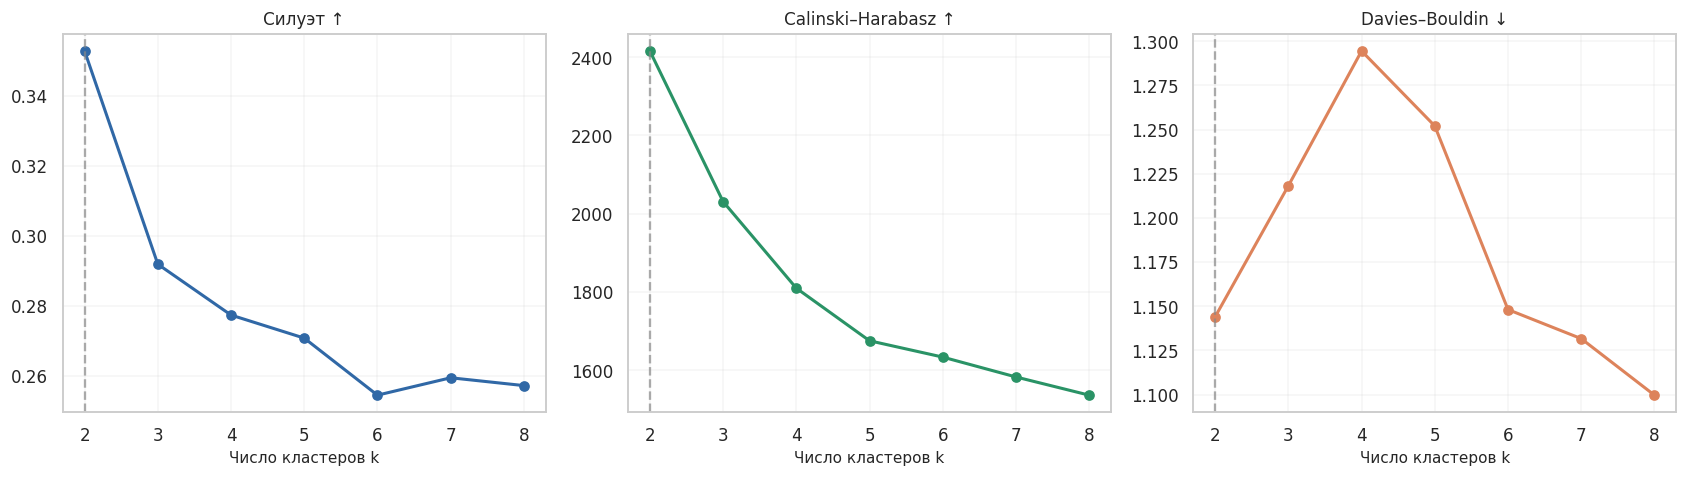

In [20]:
parameter_effect = kmeans_search_df[["Inertia", "Silhouette",
                                      "Calinski-Harabasz", "Davies-Bouldin",
                                      "Размеры кластеров"]].copy()
display(parameter_effect.round(4))

fig, axes = plt.subplots(1, 3, figsize=(15.5, 4.5))
for ax, column, title, color in zip(
    axes, ["Silhouette", "Calinski-Harabasz", "Davies-Bouldin"],
    ["Силуэт ↑", "Calinski–Harabasz ↑", "Davies–Bouldin ↓"],
    ["#3068a6", "#2a9366", "#dd835b"]
):
    ax.plot(parameter_effect.index, parameter_effect[column], marker="o",
            linewidth=2, color=color)
    ax.axvline(best_k_kmeans, ls="--", color="#888888", alpha=.7)
    ax.set_title(title)
    ax.set_xticks(K_VALUES)
    ax.set_xlabel("Число кластеров k")
    ax.grid(alpha=.2)
fig.tight_layout()
plt.show()

#### Вывод по влиянию параметра `k`

При увеличении `k` от 2 до 8 инерция снижается с **11655,6** до **4976,3** — это обязательное свойство оптимизации K-means, но не доказательство лучшей структуры. При этом Silhouette падает с **0,3527** до **0,2572**, а Calinski–Harabasz — с **2415,8** до **1536,1**. Davies–Bouldin изменяется немонотонно (для `k=2` он **1,1440**). Совместно метрики поддерживают выбранное **`k=2`**, хотя ни одна отдельная метрика не является абсолютной мерой «истинности» групп.

### 7.2. Устойчивость K-means и согласованность методов

Повторим K-means с разными `random_state` и одинаковыми `k`, `init`, `n_init=10`, `tol=1e-8` (точная сходимость центров). ARI между различными запусками сравнивает **два разбиения**, а не их номера кластеров; 1 означает полное совпадение. Также рассчитаем ARI между итогами K-means и Ward.

In [21]:
random_states = [0, 7, 21, 42, 100]
repeated_labels = {}
for seed in random_states:
    repeated_labels[seed] = KMeans(
        n_clusters=best_k_kmeans, init="k-means++", n_init=10,
        tol=1e-8, max_iter=500, random_state=seed
    ).fit_predict(X_scaled)

stability_rows = []
for a, b in combinations(random_states, 2):
    stability_rows.append({"random_state 1": a, "random_state 2": b,
                           "ARI между разбиениями": adjusted_rand_score(
                               repeated_labels[a], repeated_labels[b])})
stability_df = pd.DataFrame(stability_rows)
display(stability_df.round(4))
print("Средний ARI между запусками:",
      round(stability_df["ARI между разбиениями"].mean(), 4))
print("Минимальный ARI между запусками:",
      round(stability_df["ARI между разбиениями"].min(), 4))
methods_ari = adjusted_rand_score(kmeans_labels, agglomerative_labels)
print("ARI между K-means и Ward:", round(methods_ari, 4))

,random_state 1,random_state 2,ARI между разбиениями
0,0,7,1.0
1,0,21,1.0
2,0,42,1.0
3,0,100,1.0
4,7,21,1.0
5,7,42,1.0
6,7,100,1.0
7,21,42,1.0
8,21,100,1.0
9,42,100,1.0


Средний ARI между запусками: 1.0
Минимальный ARI между запусками: 1.0
ARI между K-means и Ward: 0.5544


#### Вывод по устойчивости

K-means с `k=2` и `n_init=10` при пяти значениях `random_state` дал **ARI = 1,0000** для всех пар запусков: на данном наборе разбиение устойчиво к проверенным инициализациям. Согласованность **между** K-means и Ward ниже (**ARI = 0,5544**), поскольку алгоритмы по-разному проводят границу между частично перекрывающимися группами. Устойчивое решение не обязано точно совпадать с ботаническими сортами.

## 8. Визуализация и интерпретация
### 8.1. PCA до двух компонент для визуализации

PCA уменьшает размерность **пяти стандартизированных признаков** до двух главных компонент. **Оба алгоритма обучены ранее на исходной пятимерной матрице**, PCA используется только для отображения их результатов. Вычисляем объяснённую дисперсию и проектируем центры тем же преобразованием. Добавляем третью панель с известными сортами исключительно для визуального **постфактум** сравнения.

Объяснённая дисперсия PC1: 0.5247
Объяснённая дисперсия PC2: 0.2934
Суммарно PC1 + PC2: 0.8181


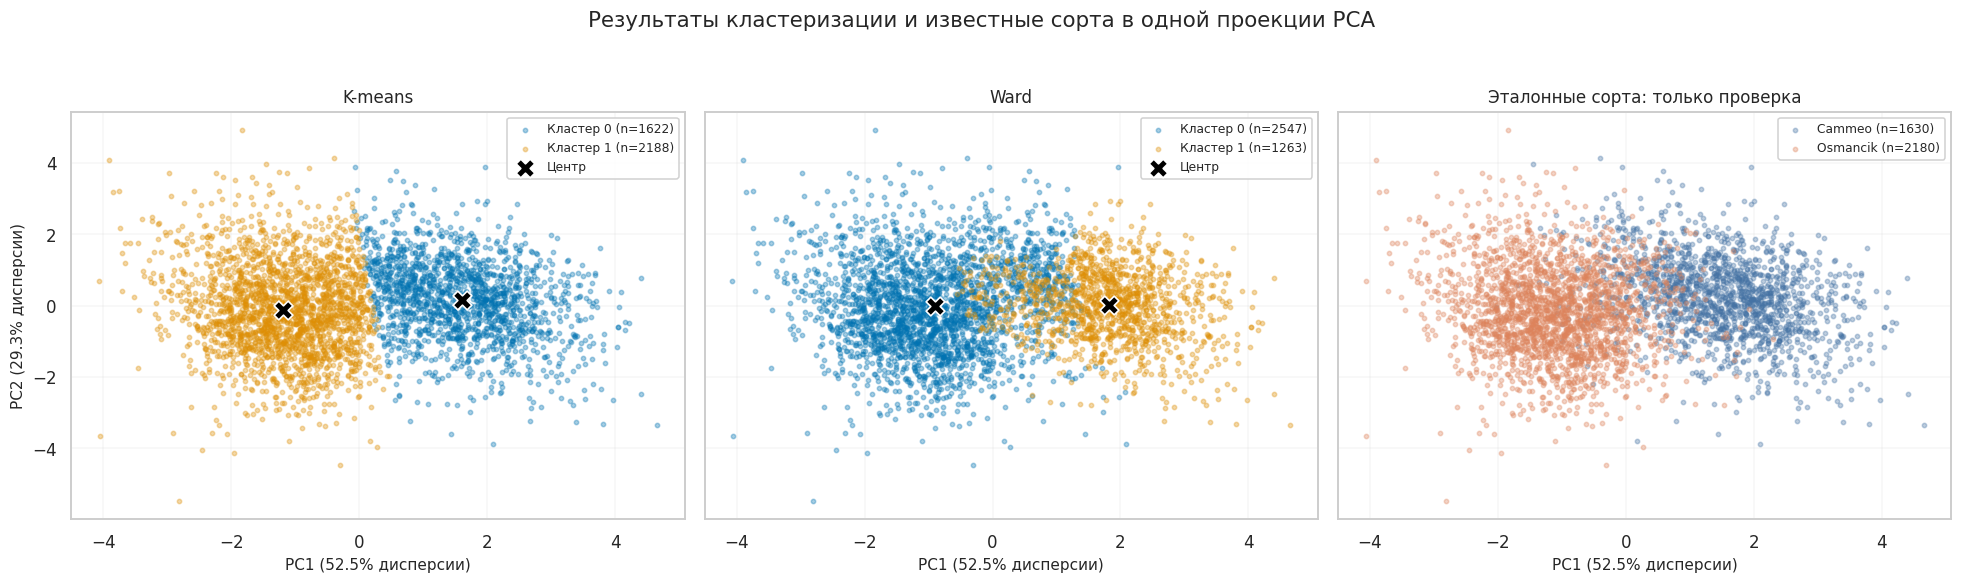

In [22]:
pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca = pca.fit_transform(X_scaled)
explained_variance = pca.explained_variance_ratio_
print("Объяснённая дисперсия PC1:", round(explained_variance[0], 4))
print("Объяснённая дисперсия PC2:", round(explained_variance[1], 4))
print("Суммарно PC1 + PC2:", round(explained_variance.sum(), 4))

fig, axes = plt.subplots(1, 3, figsize=(18, 5.4), sharex=True, sharey=True)
for ax, labels, centers, title in [
    (axes[0], kmeans_labels, kmeans_centroids, "K-means"),
    (axes[1], agglomerative_labels, agg_centroids, "Ward")
]:
    ids = sorted(np.unique(labels))
    palette = sns.color_palette("colorblind", n_colors=len(ids))
    colors = {c: palette[i] for i, c in enumerate(ids)}
    for c in ids:
        where = labels == c
        ax.scatter(X_pca[where, 0], X_pca[where, 1], s=8,
                   alpha=.34, color=colors[c], rasterized=True,
                   label=f"Кластер {c} (n={where.sum()})")
    centers_pca = pca.transform(centers)
    ax.scatter(centers_pca[:, 0], centers_pca[:, 1], marker="X", s=150,
               c="black", edgecolors="white", linewidths=1.1, zorder=5,
               label="Центр")
    ax.set_title(title)
    ax.legend(loc="best", framealpha=.9, fontsize=8)

reference_palette = {"Cammeo": "#4472a4", "Osmancik": "#dd835b"}
for cls in sorted(y_external.unique()):
    where = (y_true == cls)
    axes[2].scatter(X_pca[where, 0], X_pca[where, 1], s=8, alpha=.34,
                    color=reference_palette[cls], rasterized=True,
                    label=f"{cls} (n={where.sum()})")
axes[2].set_title("Эталонные сорта: только проверка")
axes[2].legend(loc="best", framealpha=.9, fontsize=8)
for ax in axes:
    ax.set_xlabel(f"PC1 ({explained_variance[0]*100:.1f}% дисперсии)")
    ax.grid(alpha=.16)
axes[0].set_ylabel(f"PC2 ({explained_variance[1]*100:.1f}% дисперсии)")
fig.suptitle("Результаты кластеризации и известные сорта в одной проекции PCA", fontsize=14)
fig.tight_layout(rect=[0, 0, 1, .95])
plt.show()

#### Вывод по PCA

PC1 объясняет **52,47%**, PC2 — **29,34%**, суммарно **81,81%** изменчивости стандартизированных пяти признаков. Это достаточно информативная проекция для просмотра двух групп, но не полное сохранение пятимерных расстояний. На трёх соседних графиках показаны K-means, Ward и **только для сравнения** исходные сорта. Маркеры `X` — центры, вычисленные в полном пространстве и затем перенесённые в PCA; кластеризация выполнена **до снижения размерности**.

### 8.2. Характеристики и содержательные профили кластеров

Для интерпретации центров используем средние и медианы пяти признаков в **исходных единицах**; сравниваем значения с общим средним выборки. Также построим профиль стандартизированных отклонений центров от среднего (ноль), что помогает увидеть, какие признаки отличают группы при разных масштабах.

K-means: объекты по кластерам


,Число зёрен
Кластер,
0,1622
1,2188


K-means: средние и медианы в исходных единицах


Area          Major_Axis_Length          Minor_Axis_Length         Eccentricity        Extent       
              mean   median              mean   median              mean  median         mean median   mean median
Кластер                                                                                                           
0        14292.035  14253.5           206.248  205.807            89.285  89.172        0.901  0.901  0.648  0.628
1        11463.602  11532.5           175.824  175.665            84.111  84.287        0.877  0.876  0.672  0.657

Ward: объекты по кластерам


,Число зёрен
Кластер,
0,2547
1,1263


Ward: средние и медианы в исходных единицах


Area          Major_Axis_Length          Minor_Axis_Length         Eccentricity        Extent       
              mean   median              mean   median              mean  median         mean median   mean median
Кластер                                                                                                           
0        11727.032  11730.0           178.990  177.638            84.493  84.647        0.880  0.879  0.659  0.639
1        14564.759  14547.0           208.512  208.371            89.986  89.930        0.901  0.902  0.668  0.664

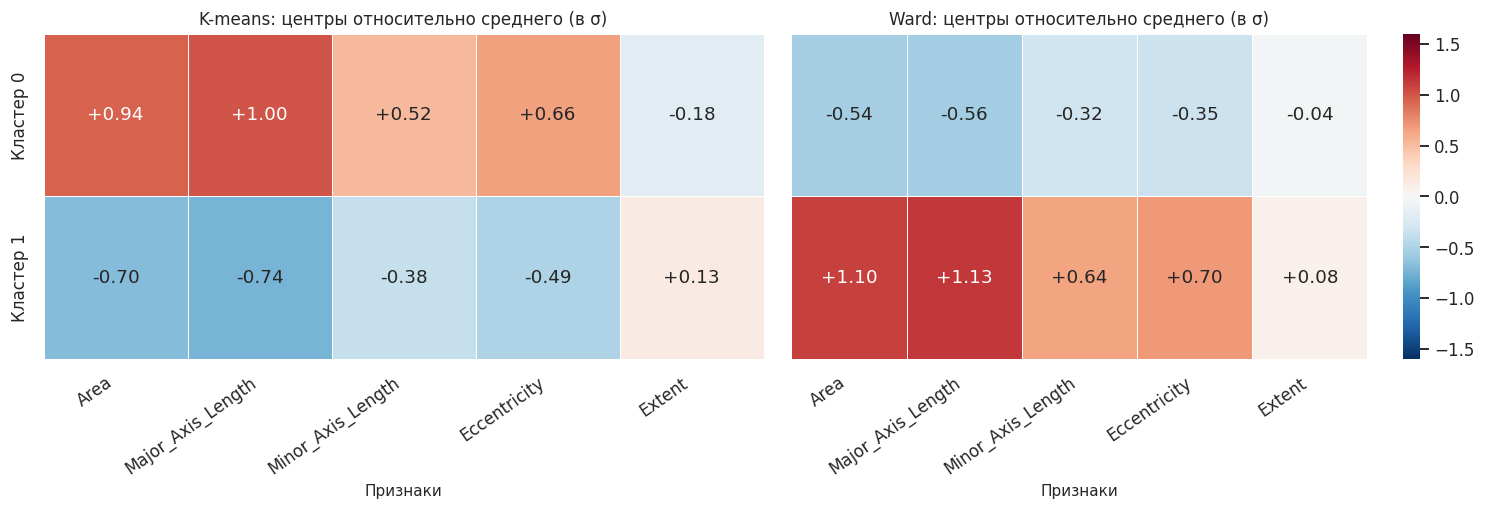

In [23]:
def profile_clusters(labels, method_name):
    prof = X_raw.copy()
    prof["Кластер"] = labels
    summary = prof.groupby("Кластер")[selected_features].agg(["mean", "median"]).round(3)
    counts = prof.groupby("Кластер").size().rename("Число зёрен")
    print(f"{method_name}: объекты по кластерам")
    display(counts.to_frame())
    print(f"{method_name}: средние и медианы в исходных единицах")
    display(summary)
    return prof, summary

profile_kmeans, numeric_cluster_profile = profile_clusters(kmeans_labels, "K-means")
profile_agg, agg_numeric_cluster_profile = profile_clusters(agglomerative_labels, "Ward")

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8), sharey=True)
for ax, centers, ids, name in [
    (axes[0], kmeans_centroids, kmeans_cluster_ids, "K-means"),
    (axes[1], agg_centroids, agg_cluster_ids, "Ward")
]:
    center_df = pd.DataFrame(centers, index=[f"Кластер {i}" for i in ids],
                             columns=selected_features)
    sns.heatmap(center_df, annot=True, fmt="+.2f", center=0,
                cmap="RdBu_r", vmin=-1.6, vmax=1.6, linewidths=.5,
                cbar=ax is axes[1], ax=ax)
    ax.set_title(f"{name}: центры относительно среднего (в σ)")
    ax.set_xlabel("Признаки")
    ax.set_ylabel("")
    ax.set_xticklabels(ax.get_xticklabels(), rotation=35, ha="right")
fig.tight_layout()
plt.show()

#### Интерпретация выделенных групп

**K-means (`k=2`):**

- **Кластер 0 — более крупные и вытянутые зёрна (1622 объекта).** Средняя площадь **14292,0 пикселей²**, большая ось **206,25**, малая ось **89,29**, эксцентриситет **0,901**, `Extent` **0,648**. Положительные стандартизированные отклонения площади и длины главной оси указывают на сравнительно крупную и вытянутую форму.
- **Кластер 1 — более мелкие и менее вытянутые зёрна (2188 объектов).** Средняя площадь **11463,6 пикселей²**, большая ось **175,82**, малая ось **84,11**, эксцентриситет **0,877**, `Extent` **0,672**. Относительно меньшая эксцентриситетность указывает на менее вытянутую форму.

**Ward (`k=2`):** кластер 0 (2547 зёрен) имеет площадь в среднем **11727,0**, а кластер 1 (1263 зёрен) — **14564,8** пикселей². Большая ось соответственно **178,99** и **208,51**, эксцентриситет **0,880** и **0,901**. Таким образом, оба метода обнаруживают осмысленную ось различий **«небольшие/менее вытянутые» — «крупные/вытянутые»**, однако по-разному определяют пограничные объекты. Номера кластеров в двух алгоритмах **не совпадают по смыслу**. Соответствие сортам проверено отдельно (таблица сопряжённости, раздел 6.3).

## 9. Сравнение двух методов

Объединим число кластеров, их размеры, внутренние и внешние метрики, компактность и согласованность. Разбиения получены на **одном наборе из пяти стандартизированных признаков**. Силуэт в итоговой таблице рассчитан по всем 3810 точкам. Для разных `k` показатели компактности и силуэт нужно интерпретировать совместно, а не выводить победителя по единственной цифре.

In [24]:
comparison_rows = []
for name, labels, intern, compactness in [
    ("K-means", kmeans_labels, kmeans_metrics, kmeans_compactness),
    ("Agglomerative (Ward)", agglomerative_labels,
     agglomerative_metrics, agg_compactness)
]:
    external = external_comparison.loc[name]
    comparison_rows.append({
        "Метод": name, "Число кластеров": len(np.unique(labels)),
        "Размеры кластеров": sorted(pd.Series(labels).value_counts().tolist(), reverse=True),
        "Silhouette": intern["Silhouette"],
        "Calinski-Harabasz": intern["Calinski-Harabasz"],
        "Davies-Bouldin": intern["Davies-Bouldin"],
        "Средняя компактность": np.average(compactness["Среднее расстояние"],
                                             weights=compactness["Количество"]),
        "ARI vs Class": external["ARI"], "NMI vs Class": external["NMI"]
    })
final_comparison = pd.DataFrame(comparison_rows).set_index("Метод")
display(final_comparison.round(4))
print("ARI между решениями двух методов:", round(methods_ari, 4))

better_sil = final_comparison["Silhouette"].idxmax()
print("Лидер по точному силуэту:", better_sil)

,Число кластеров,Размеры кластеров,Silhouette,Calinski-Harabasz,Davies-Bouldin,Средняя компактность,ARI vs Class,NMI vs Class
Метод,,,,,,,,
K-means,2,"[2188, 1622]",0.3523,2415.8410,1.144,1.6128,0.6991,0.5862
Agglomerative (Ward),2,"[2547, 1263]",0.3142,1925.6077,1.204,1.6805,0.5251,0.4494


ARI между решениями двух методов: 0.5544
Лидер по точному силуэту: K-means


### Вывод по сравнению методов

На полной выборке **K-means показывает лучшие внутренние показатели**, чем Ward: **Silhouette 0,3523 против 0,3142**, **Calinski–Harabasz 2415,84 против 1925,61**, **Davies–Bouldin 1,144 против 1,204** (для последней метрики меньше — лучше). Его взвешенное среднее расстояние объекта до центра также ниже: **1,613 против 1,681**. Оба метода выбрали **две группы**, но размеры отличаются: **2188/1622** у K-means и **2547/1263** у Ward. Внешняя проверка тоже выше для K-means (**ARI 0,6991 против 0,5251**), при этом **эти метрики не использовались при настройке**. Согласованность алгоритмов умеренная (**ARI 0,5544**), что объясняется частичным перекрытием облаков и разной геометрией разбиения. По совокупности результатов в рамках выбранных признаков и евклидова расстояния **предпочтителен K-means**.

## 10. Заключение

Проведена кластеризация **3810 зёрен риса** из набора *Rice (Cammeo and Osmancik)*. Проверены размерность, пропуски (0), дубликаты (0), распределения, корреляции и потенциальные выбросы. По IQR среди выбранных признаков **85 наблюдений (2,23%)** имеют хотя бы один флаг; их сохранили как вероятные реальные геометрические варианты. Для кластеризации без учителя отобраны **5 числовых признаков** (`Area`, `Major_Axis_Length`, `Minor_Axis_Length`, `Eccentricity`, `Extent`); избыточные `Perimeter` и `Convex_Area` исключены. Метки `Class` отложены для независимой проверки. Выполнена стандартизация `StandardScaler`.

Выполнены **K-means** и **Agglomerative Clustering (Ward)**, подбор числа групп методом локтя, силуэта и дендрограммой. Оба метода предпочли **`k=2`**. В итоговом сравнении K-means лучше по Silhouette (**0,3523** против **0,3142**), Calinski–Harabasz (**2415,8** против **1925,6**), Davies–Bouldin (**1,144** против **1,204**). K-means устойчив к пяти проверенным случайным инициализациям (попарный **ARI=1**). Между методами наблюдается умеренное согласие (**ARI=0,5544**). Внешняя оценка по исходным сортам показывает для K-means **ARI=0,6991**, для Ward **0,5251**; классы не участвовали в построении групп.

**Содержательная интерпретация:** группировка прежде всего отражает размер и вытянутость: у K-means выделяются **1622 более крупных и вытянутых** зерна (площадь ≈ **14292**) и **2188 более мелких** (площадь ≈ **11464**). Соседние точки разных сортов геометрически перекрываются; кластеры не обязаны полностью воспроизводить исходную классификацию. PCA сохраняет **81,81%** дисперсии в двух компонентах и используется только для графиков. **Вывод:** в рамках выбранных признаков K-means эффективнее Ward, но оценка ограничена евклидовой метрикой, коррелированностью измерений и реальным перекрытием распределений.

## 11. Список источников

1. UCI Machine Learning Repository. **Rice (Cammeo and Osmancik)**. https://archive.ics.uci.edu/dataset/545/rice+cammeo+and+osmancik (обращение: 07.11.2026).
2. Pedregosa F. et al. **Scikit-learn: Machine Learning in Python**. *Journal of Machine Learning Research*, 12, 2825–2830, 2011. https://scikit-learn.org/stable/.
3. SciPy. **Hierarchical clustering (`linkage`, `dendrogram`, `cut_tree`)**. https://docs.scipy.org/doc/scipy/reference/cluster.hierarchy.html.
4. Seaborn. **Statistical data visualization**. https://seaborn.pydata.org/.
5. Теоретические материалы по лабораторной работе, слайды 104–124: алгоритмы K-means, Ward, метод локтя, silhouette и внешние индексы (предоставленный файл `теория.DOCX`).

## 12. Приложение: полный листинг программного кода

Весь исполняемый Python-код приведён **непосредственно в кодовых ячейках этого ноутбука**, последовательно от загрузки ARFF до сравнения алгоритмов. Для удобства проверки дополнительно экспортирован самостоятельный файл `laba3_clustering_rice.py` с тем же листингом. Для запуска нужны исходный `Rice_Cammeo_Osmancik.arff` в текущем рабочем каталоге и библиотеки `numpy`, `pandas`, `scipy`, `scikit-learn`, `matplotlib`, `seaborn`, `IPython`.